<h1>1. Informacje o zbiorze</h1>
<p>Dane pochodzą z publicznego zbioru danych <strong>National Institutes of Health</strong><p>
<ul>
<li><a href="https://irp.nih.gov/news-and-events/in-the-news/nih-clinical-center-provides-one-of-the-largest-publicly-available-chest-x">Link do opisu zbioru <a></li>
<li><a href="https://nihcc.app.box.com/v/ChestXray-NIHCC">Link do zbioru</a></li>
</ul>

<h1>2. Eksploracja zbioru danych</h1>

<h2>2.1. Import bibliotek</h2>

In [23]:
import os.path

import PIL
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from torchvision import transforms

<h2>2.2. Wczytanie pliku z opisem danych</h2>

<p>W udostępnionym zbiorze danych znajduje się plik <strong><em>Data_Entry_2017_v2020.csv</em></strong> zawierający dane o pacjentach
</p>

In [24]:
images_df = pd.read_csv("Data_Entry_2017_v2020.csv")
images_df.sample(10)

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
43329,00011174_009.png,No Finding,9,11174,48,M,AP,2500,2048,0.168,0.168
17106,00004584_002.png,No Finding,2,4584,60,M,PA,2992,2991,0.143,0.143
79332,00019479_010.png,Nodule,10,19479,33,F,AP,2500,2048,0.168,0.168
47391,00012045_023.png,Edema|Effusion,23,12045,44,F,AP,2500,2048,0.168,0.168
101929,00027108_012.png,No Finding,12,27108,59,F,AP,3056,2544,0.139,0.139
87775,00021703_000.png,Atelectasis,1,21703,24,M,PA,3024,2456,0.139,0.139
81818,00020127_001.png,No Finding,0,20127,37,M,PA,3056,2488,0.139,0.139
2052,00000531_003.png,No Finding,1,531,47,M,PA,2500,2048,0.168,0.168
19103,00005069_000.png,No Finding,15,5069,28,F,PA,2544,3056,0.139,0.139
24869,00006527_001.png,No Finding,1,6527,49,F,AP,2500,2048,0.168,0.168


<p>Opis kolumn:</p>
<ul>
  <li><strong>Image Index</strong> – nazwa pliku obrazu (np. <code>00000001_000.png</code>)</li>
  <li><strong>Finding Labels</strong> – etykiety chorób zidentyfikowane na obrazie (np. <code>Pneumonia|Infiltration</code>, <code>No Finding</code>) - 14 schorzeń, w kolumnie może znajdować się wiele skorzeń oddzielone znakiem <code>|</code></li>
  <li><strong>Follow-up #</strong> – numer badania danego pacjenta (do śledzenia wielu badań jednej osoby)</li>
  <li><strong>Patient ID</strong> – unikalny identyfikator pacjenta, jeden pacjent może mieć wiele zdjęć na przestrzeni wielu lat</li>
  <li><strong>Patient Age</strong> – wiek pacjenta (w latach)</li>
  <li><strong>Patient Gender</strong> – płeć pacjenta (<code>M - mężczyzna</code> lub <code>F - kobieta</code>)</li>
  <li><strong>View Position</strong> – pozycja podczas wykonywania zdjęcia (<code>PA</code>, <code>AP</code>, opis pozycji znajduje się poniżej)</li>
  <li><strong>OriginalImage[Width/Height]</strong> – oryginalne wymiary obrazu, jako dwie kolumny - nie będą używane w poniższej analizie</li>
  <li><strong>OriginalImagePixelSpacing[x/y]</strong> – rozdzielczość w mm/piksel, jako dwie kolumny - nie będą używane w poniższej analizie</li>
</ul>

<h2>PA i AP – Projekcje w rentgenie klatki piersiowej</h2>

<h3><strong>PA (Posteroanterior)</strong> – projekcja tylno-przednia</h3>
<ul>
  <li>Promienie rentgenowskie przechodzą <strong>od pleców (posterior)</strong> do <strong>przodu ciała (anterior)</strong>.</li>
  <li>Pacjent stoi przodem do detektora, a źródło promieniowania znajduje się za nim.</li>
  <li><strong>To standardowa i preferowana projekcja</strong> w rutynowych badaniach, ponieważ:
    <ul>
      <li>serce znajduje się bliżej detektora i nie jest powiększone na obrazie,</li>
      <li>obraz jest bardziej dokładny i mniej zniekształcony.</li>
    </ul>
  </li>
</ul>

<h3><strong>AP (Anteroposterior)</strong> – projekcja przednio-tylna</h3>
<ul>
  <li>Promienie przechodzą <strong>od przodu ciała (anterior)</strong> do <strong>pleców (posterior)</strong>.</li>
  <li>Pacjent ma detektor za plecami, a promieniowanie pada z przodu.</li>
  <li>Stosowana, gdy pacjent <strong>nie może wstać</strong> (np. leży w łóżku, na OIOM-ie).</li>
  <li><strong>Wady:</strong>
    <ul>
      <li>serce wydaje się większe niż w rzeczywistości (jest dalej od detektora),</li>
      <li>większe ryzyko zniekształceń obrazu.</li>
    </ul>
  </li>
</ul>

<p>Źródło:</p>
<ul>
<li><a href="https://radiopaedia.org/articles/chest-pa-view-1">PA</a></li>
<li><a href="https://radiopaedia.org/articles/chest-ap-erect-view-1">AP</a></li>
</ul>

<h3>2.3. Podstawowe informacje o kolumnach</h3>

In [25]:
images_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112120 entries, 0 to 112119
Data columns (total 11 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Image Index                  112120 non-null  object 
 1   Finding Labels               112120 non-null  object 
 2   Follow-up #                  112120 non-null  int64  
 3   Patient ID                   112120 non-null  int64  
 4   Patient Age                  112120 non-null  int64  
 5   Patient Gender               112120 non-null  object 
 6   View Position                112120 non-null  object 
 7   OriginalImage[Width          112120 non-null  int64  
 8   Height]                      112120 non-null  int64  
 9   OriginalImagePixelSpacing[x  112120 non-null  float64
 10  y]                           112120 non-null  float64
dtypes: float64(2), int64(5), object(4)
memory usage: 9.4+ MB


<h3>2.4. Usuwam kolumny z informacją o wymiarach, bo nie będą one używane w analizie.</h3>

In [26]:
images_df.drop(
    columns=["OriginalImage[Width", "Height]", "OriginalImagePixelSpacing[x", "y]"],
    inplace=True,
)
images_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112120 entries, 0 to 112119
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   Image Index     112120 non-null  object
 1   Finding Labels  112120 non-null  object
 2   Follow-up #     112120 non-null  int64 
 3   Patient ID      112120 non-null  int64 
 4   Patient Age     112120 non-null  int64 
 5   Patient Gender  112120 non-null  object
 6   View Position   112120 non-null  object
dtypes: int64(3), object(4)
memory usage: 6.0+ MB


<h3>2.5. Zmieniam typy danych na kategoryczne, aby zoptymalizować sposób przechowywania danych w pamięci</h3>

In [27]:
images_df["Follow-up #"] = images_df["Follow-up #"].astype("category")
images_df["Patient ID"] = images_df["Patient ID"].astype("category")
images_df["Patient Gender"] = images_df["Patient Gender"].astype("category")
images_df["View Position"] = images_df["View Position"].astype("category")
images_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112120 entries, 0 to 112119
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   Image Index     112120 non-null  object  
 1   Finding Labels  112120 non-null  object  
 2   Follow-up #     112120 non-null  category
 3   Patient ID      112120 non-null  category
 4   Patient Age     112120 non-null  int64   
 5   Patient Gender  112120 non-null  category
 6   View Position   112120 non-null  category
dtypes: category(4), int64(1), object(2)
memory usage: 4.5+ MB


<h3>2.6. Sprawdzam czy mamy zduplikowane wiersze i kolumny</h3>

In [28]:
duplicated_rows = images_df.duplicated(keep=False)
duplicated_columns = images_df.T.duplicated(keep=False)
print("Zduplikowane wiersze:", duplicated_rows.sum())
print("Zduplikowane kolumny:", duplicated_columns.sum())

Zduplikowane wiersze: 0
Zduplikowane kolumny: 0


<h3>2.7. Sprawdzam czy w zbiorze występują brakujące dane</h3>

In [29]:
images_df.isnull().sum() / len(images_df)

Image Index       0.0
Finding Labels    0.0
Follow-up #       0.0
Patient ID        0.0
Patient Age       0.0
Patient Gender    0.0
View Position     0.0
dtype: float64

<h3>2.8. Sprawdzam unikalne wartości w podziale na kolumny</h3>

In [30]:
images_df.nunique()

Image Index       112120
Finding Labels       836
Follow-up #          184
Patient ID         30805
Patient Age           96
Patient Gender         2
View Position          2
dtype: int64

<p><strong>W zbiorze znajduję się opis 112120 unikalnych zdjęć dla 30805 pacjentów</strong></p>

<h2>3. Transformacja danych - binary encoding</h2>

<p>Schorzenia w kolumnie <code>Finding Labels</code> występują oddzielone znakiem <code>|</code> (pipe), na potrzeby analizy dokonuje transformacji powyższej kolumny na 14 osobnych kolumn (14 schorzeń), gdzie poprzez wartość 1 oznaczone będzie, że dane schorznie występuje na zdjęciu lub 0 jeśli schorzenie nie występuje.</p>

In [31]:
# definijemy stałe
# kolumny ze zbioru które nas interesują
COLUMNS = [
    "Image Index",
    "Finding Labels",
    "Follow-up #",
    "Patient ID",
    "Patient Age",
    "Patient Gender",
    "View Position",
]

# lista schorzeń
DISEASES = [
    "Cardiomegaly",  # Kardiomegalia (powiększenie serca)
    "Emphysema",  # Rozedma
    "Effusion",  # Wysięk
    "Hernia",  # Przepuklina
    "Infiltration",  # Nacieki
    "Mass",  # Masa plucna
    "Nodule",  # Guzki
    "Atelectasis",  # Niedodma
    "Pneumothorax",  # Odma opłucnowa
    "Pleural_Thickening",  # Pogrubienie opłucnej
    "Pneumonia",  # Zapalenie płuc
    "Fibrosis",  # Zwłóknienie
    "Edema",  # Obrzęk
    "Consolidation",  # Konsolidacja (zagęszczenie miąższu płuca)
]
assert len(DISEASES) == 14

FINDING_LABELS = "Finding Labels"
transformed_df = images_df[COLUMNS].copy()
# robię "split" schorzeń z kolumny "Finding Labels" i zapisuje jako listę
transformed_df[FINDING_LABELS] = transformed_df[FINDING_LABELS].apply(
    lambda x: x.split("|")
)
# jeśli dane schorzenie występuje w liście schorzeń dla danego wiersza to w kolumnie tego schorzenia ustawiamy 1, w przeciwnym wypadku 0
for label in DISEASES:
    transformed_df[label] = transformed_df[FINDING_LABELS].apply(
        lambda row_finding_labels: int(label in row_finding_labels)
    )
# po zakodowaniu schorzeń w osobnych kolumnach usuwam kolumnę "Finding Labels"
transformed_df.drop(columns=[FINDING_LABELS], inplace=True)

# lista unikatowych pacjentów
patients_ids = list(transformed_df["Patient ID"].unique())

# liczba unikatowych pacjentów
total_number_of_patients = len(patients_ids)
print(f"Liczba pacjentów: {total_number_of_patients}")
transformed_df.sample(10)

Liczba pacjentów: 30805


,Image Index,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,Cardiomegaly,Emphysema,Effusion,Hernia,Infiltration,Mass,Nodule,Atelectasis,Pneumothorax,Pleural_Thickening,Pneumonia,Fibrosis,Edema,Consolidation
59145,00014626_042.png,41,14626,45,F,AP,0,0,0,0,1,0,0,0,1,0,0,0,0,0
66084,00016333_009.png,4,16333,46,M,AP,0,0,0,0,1,0,0,1,0,0,0,0,1,0
32585,00008522_008.png,8,8522,60,F,AP,0,0,0,0,1,0,0,0,0,0,0,0,0,1
88742,00021988_005.png,9,21988,18,M,PA,0,0,0,0,1,0,0,0,0,0,0,0,0,0
59067,00014617_007.png,7,14617,58,F,PA,0,0,1,0,0,1,1,1,0,0,0,0,0,1
74954,00018385_001.png,2,18385,61,F,AP,0,0,0,0,0,0,0,0,0,0,0,0,0,0
45937,00011760_003.png,2,11760,35,F,AP,0,0,0,0,0,0,0,0,0,0,0,0,0,0
38410,00010042_007.png,7,10042,44,M,PA,0,0,0,0,0,0,0,0,0,0,0,1,0,0
2227,00000583_018.png,17,583,40,F,AP,0,0,1,0,0,0,0,0,0,0,0,0,0,1
8417,00002233_000.png,0,2233,61,F,PA,0,0,0,0,0,0,0,0,0,0,0,0,0,0


<h2>4. Podział zbioru na część testową i treningowo-walidacyjną</h2>

<p>Przed dalszą analizą danych, dzielę losowo zbiór na część testową 10% i treningowo walidacyjną 90%. Podziału dokonuję po identyfikatorze pacjenta, tak by jego zdjęcia nie występowały jednocześnie w częsci testowej i treningowo-walidującej.</p>

In [32]:
# nazwa katalogu w którym zapiszę podzielone zbiory
DATASET_OUTPUT_DIR = "dataset_labels"
# prefix scieżki do pliku zbioru
DATASET_CSV_PATH_PREFIX = os.path.join(DATASET_OUTPUT_DIR, "nih_labels")

In [33]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)

train_val_idx, test_idx = next(
    gss.split(transformed_df, groups=transformed_df["Patient ID"])
)
# zbiór treningowo-walidujący
train_val_df = transformed_df.iloc[train_val_idx]

# zbiór testowy
test_df = transformed_df.iloc[test_idx]

print(f"Liczba pacjentów w zbiorze TESTOWYM: {len(test_df['Patient ID'].unique())}")
print(f"Liczba zdjęć w zbiorze TESTOWYM: {len(test_df)}")
print()
print(f"Liczba pacjentów w zbiorze TRENINGOWO-WALIDUJĄCYM: {len(train_val_df['Patient ID'].unique())}")
print(f"Liczba zdjęć w zbiorze TRENINGOWO-WALIDUJĄCYM: {len(train_val_df)}")

# walidacja czy zdjęcia pacjenta nie występują jednocześnie w obu zbiorach
assert set(train_val_df["Patient ID"]).isdisjoint(test_df['Patient ID'])

Liczba pacjętów w zbiorze TESTOWYM: 3081
Liczba zdjęć w zbiorze TESTOWYM: 10950

Liczba pacjętów w zbiorze TRENINGOWO-WALIDUJĄCYM: 27724
Liczba zdjęć w zbiorze TRENINGOWO-WALIDUJĄCYM: 101170


<h3>4.1. Zapis pliku ze zbiorem testowym</h3>

In [34]:
test_df.to_csv(f"{DATASET_CSV_PATH_PREFIX}_test.csv", index=False)

<h3>4.2. Zapis pliku ze zbiorem treningowo-walidującym</h3>

In [35]:
train_val_df.to_csv(f"{DATASET_CSV_PATH_PREFIX}_train_val.csv", index=False)

<h2>5. Przegląd rozkładów zmiennych ze zbioru</h2>

<h3>5.1. Definicja funkcji pomocniczej do rysowania histogramów</h3>

In [36]:
def plot_histogram(df, label, bins):
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, bins=bins, edgecolor="white")
    plt.xlabel(label, fontsize=12)
    plt.ylabel("Częstość", fontsize=12)
    plt.title(f"Rozkład zmiennej - {label}", fontsize=14, weight="bold")
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    plt.tight_layout()
    plt.show()

<h3>5.2. Rozkład zmiennej <code>Wiek Pacjęta</code> w zbiorze treningowo-walidującym</h3>

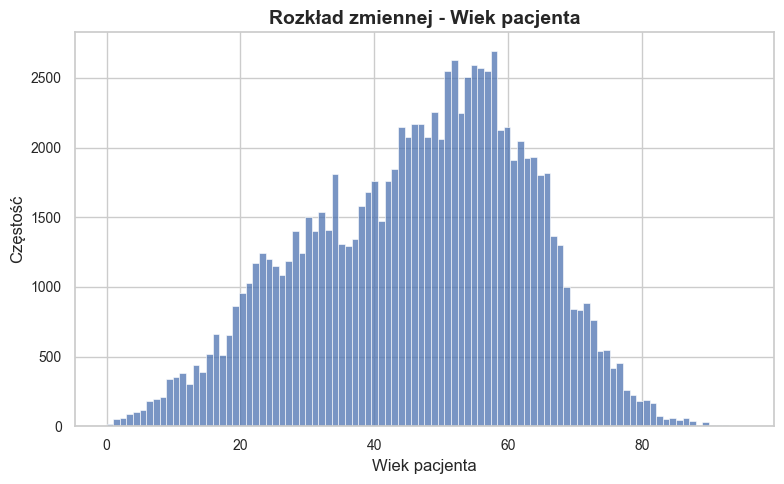

In [37]:
plot_histogram(
    train_val_df["Patient Age"],
    "Wiek pacjenta",
    len(train_val_df["Patient Age"].unique()),
)

<h3>5.3. Podstawowe statystyki zmiennej <code>Wiek Pacjęta</code> w zbiorze treningowo-walidującym</h3>

In [38]:
train_val_df["Patient Age"].describe()

count    101170.000000
mean         46.597035
std          16.607018
min           0.000000
25%          34.000000
50%          49.000000
75%          59.000000
max          95.000000
Name: Patient Age, dtype: float64

<h3>5.4. Wykres pudełkowy zmiennej <code>Wiek Pacjęta</code> w podziale na <code>Płeć</code> w zbiorze treningowo-walidującym</h3>

<Axes: xlabel='Patient Gender', ylabel='Patient Age'>

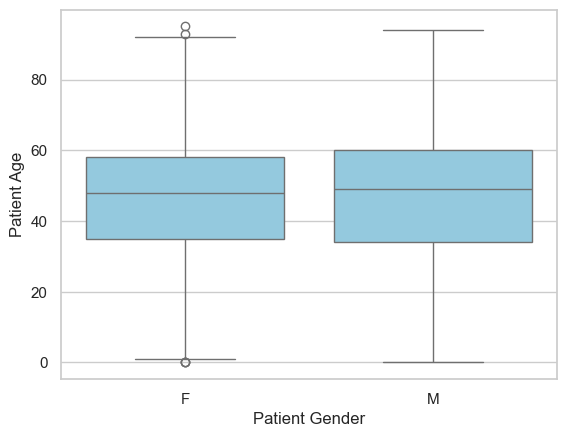

In [39]:
sns.boxplot(x="Patient Gender", y="Patient Age", data=train_val_df, color="skyblue")

<h3>5.5. Rozkład zmiennej <code>Płeć</code> w zbiorze treningowo-walidującym</h3>

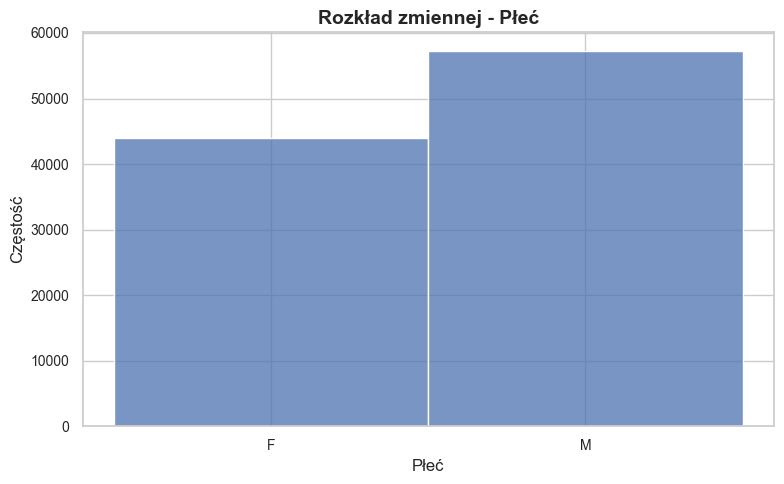

In [40]:
plot_histogram(
    train_val_df["Patient Gender"],
    "Płeć",
    len(train_val_df["Patient Gender"].unique()),
)

<h3>5.6. Rozkład zmiennej <code>Projekcja</code> w zbiorze treningowo-walidującym</h3>

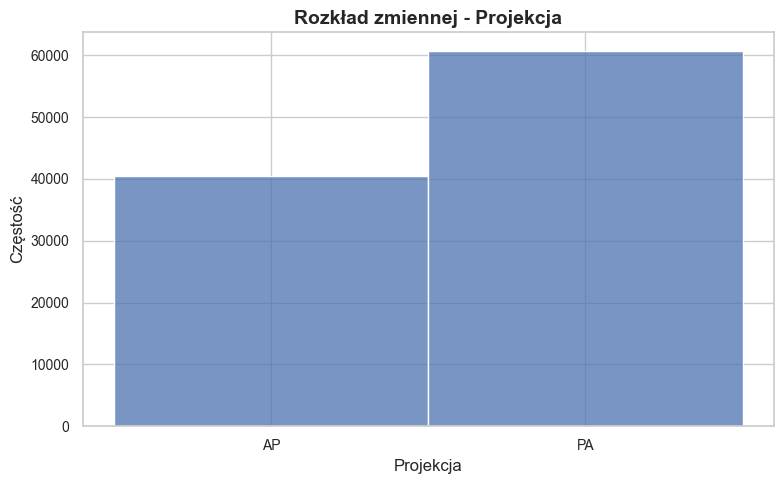

In [41]:
plot_histogram(
    train_val_df["View Position"],
    "Projekcja",
    len(train_val_df["View Position"].unique()),
)

<h3>5.7. Rozkład poszczególnych schorzeń w zbiorze treningowo-walidującym</h3>

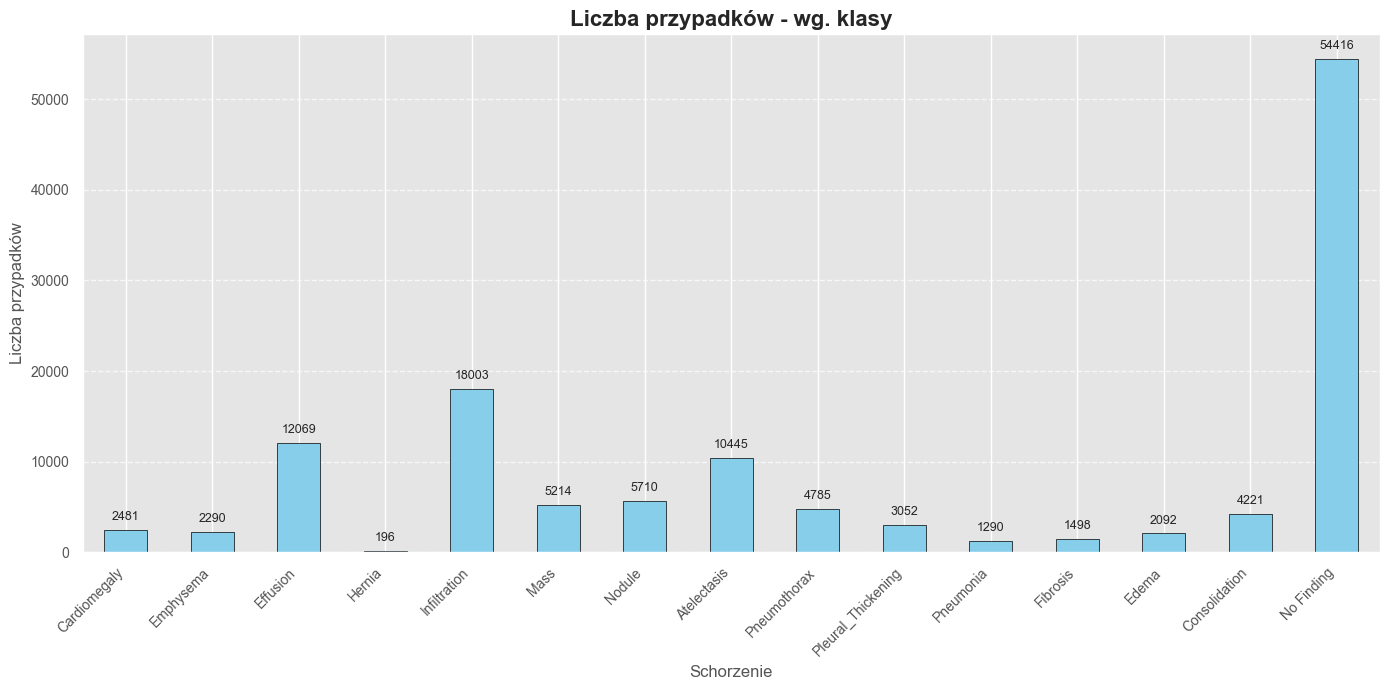

In [42]:
def plot_dataset_histogram(df):
    disease_counts = (df[DISEASES] == 1).sum(axis=0)
    no_findings = df[(df[DISEASES] == 0).all(axis=1)]
    disease_counts = pd.concat(
        [disease_counts, pd.Series({"No Finding": len(no_findings)})]
    )
    plt.style.use("ggplot")
    fig, ax = plt.subplots(figsize=(14, 7))
    bars = disease_counts.plot(kind="bar", ax=ax, color="skyblue", edgecolor="black")
    ax.set_title(f"Liczba przypadków - wg. klasy", fontsize=16, weight="bold")
    ax.set_xlabel("Schorzenie", fontsize=12)
    ax.set_ylabel("Liczba przypadków", fontsize=12)
    plt.xticks(rotation=45, ha="right", fontsize=10)
    plt.yticks(fontsize=10)
    for bar in bars.patches:
        height = bar.get_height()
        ax.annotate(
            f"{int(height)}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )
    plt.tight_layout()
    plt.grid(True, axis="y", linestyle="--", alpha=0.7)
    plt.show()


plot_dataset_histogram(train_val_df)

<h2>6. K-Fold - walidacja krzyżowa</h2>
<p>Podczas trenowania modelu będe używał walidacji krzyżowej aby:</p>
<ul>
<li>Polepszyć generalizację modelu</li>
<li>Zminimalizować ryzyko przeuczenia</li>
<li>Odpowiednio dobrać wartości hiperparametrów</li>
</ul>

<h3>6.1. Podział zbioru na 5 foldów</h3>
<ul>
<li>Każdy element zbioru będzie użyty raz jako element zbioru walidującego i cztery razy jako element zbioru treningowego</li>
<li>Podziału dokonuję podobnie jak przy wyodrębnieniu zbioru testowego, po identyfikatorze pacjenta</li>
</ul>

In [43]:
def train_set_file_name(fold):
    return f"{DATASET_CSV_PATH_PREFIX}_train_f{fold}.csv"


def validation_set_file_name(fold):
    return f"{DATASET_CSV_PATH_PREFIX}_val_f{fold}.csv"


gkf = GroupKFold(n_splits=5)
folds = list(gkf.split(train_val_df, groups=train_val_df["Patient ID"]))
fold_num = 1
for train_idx, val_idx in folds:
    train_df = train_val_df.iloc[train_idx]
    val_df = train_val_df.iloc[val_idx]
    assert set(train_df["Patient ID"]).isdisjoint(val_df["Patient ID"])
    print(f"FOLD {fold_num}:")
    print(f"Liczba pacjentów w zbiorze TRENINGOWYM: {len(train_df['Patient ID'].unique())}")
    print(f"Liczba zdjęć w zbiorze TRENINGOWYM: {len(train_df)}")
    print()
    print(f"Liczba pacjentów w zbiorze WALIDUJĄCYM: {len(val_df['Patient ID'].unique())}")
    print(f"Liczba zdjęć w zbiorze WALIDUJĄCYM: {len(val_df)}")
    print("-" * 60)
    # zapis zbioru treningowego dla danego fold'a
    train_df.to_csv(train_set_file_name(fold_num), index=False)
    # zapis zbioru walidującego dla danego fold'a
    val_df.to_csv(validation_set_file_name(fold_num), index=False)
    fold_num += 1

FOLD 1:
Liczba pacjętów w zbiorze TRENINGOWYM: 22180
Liczba zdjęć w zbiorze TRENINGOWYM: 80936

Liczba pacjętów w zbiorze WALIDUJĄCYM: 5544
Liczba zdjęć w zbiorze WALIDUJĄCYM: 20234
------------------------------------------------------------
FOLD 2:
Liczba pacjętów w zbiorze TRENINGOWYM: 22179
Liczba zdjęć w zbiorze TRENINGOWYM: 80936

Liczba pacjętów w zbiorze WALIDUJĄCYM: 5545
Liczba zdjęć w zbiorze WALIDUJĄCYM: 20234
------------------------------------------------------------
FOLD 3:
Liczba pacjętów w zbiorze TRENINGOWYM: 22179
Liczba zdjęć w zbiorze TRENINGOWYM: 80936

Liczba pacjętów w zbiorze WALIDUJĄCYM: 5545
Liczba zdjęć w zbiorze WALIDUJĄCYM: 20234
------------------------------------------------------------
FOLD 4:
Liczba pacjętów w zbiorze TRENINGOWYM: 22179
Liczba zdjęć w zbiorze TRENINGOWYM: 80936

Liczba pacjętów w zbiorze WALIDUJĄCYM: 5545
Liczba zdjęć w zbiorze WALIDUJĄCYM: 20234
------------------------------------------------------------
FOLD 5:
Liczba pacjętów w zb

<h2>7. Wyświetlam przykładowe losowe zdjęcia ze zbioru</h2>
<ul>
<li>W tytule zdjęcia znajduje się identyfikator pacjenta</li>
<li>Pod zdjęciem znajduje się lista zidentyfikowanych schorzeń</li>
</ul>

FileNotFoundError: [Errno 2] No such file or directory: 'images/00022260_003.png'



In [44]:
def show_images_grid(df, rows, cols, width, height):
    normalizer = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224)
    ])
    fig, axes = plt.subplots(rows, cols, figsize=(cols * width, rows * height))
    axes = axes.flatten()

    for i in range(rows * cols):
        image = normalizer(PIL.Image.open(f"images/{df.iloc[i]['Image Index']}").convert("RGB"))
        ax = axes[i]
        ax.imshow(image, cmap='gray')
        ax.set_title(f"ID: {df.iloc[i]['Patient ID']}", fontsize=10)
        left_pos = 0
        start = -0.05
        step = -0.05
        classes = df.iloc[i]['Finding Labels'].split("|")
        for c in classes:
            ax.text(left_pos, start, c, ha='left', va='top', fontsize=10, transform=ax.transAxes)
            start += step
        ax.axis('off')

    plt.tight_layout()
    plt.show()


width = 4
height = 5.5
rows = 50
cols = 3

dataset = pd.read_csv("Data_Entry_2017_v2020.csv")
examples = dataset.sample(rows * cols, random_state=42)
show_images_grid(examples, rows, cols, width, height)